Practical NO.04  
Name - Sakshi Vijaykumar Muthiyan  
Roll No. -  
Title:  Implement Agglomerative hierarchical clustering algorithm using appropriate dataset.

In [16]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA 
from sklearn.cluster import AgglomerativeClustering 
from sklearn.preprocessing import StandardScaler, normalize 
from sklearn.metrics import silhouette_score 
import scipy.cluster.hierarchy as shc 

In [18]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
# Generating high-density genuine-like points for solid round clusters
np.random.seed(1)
dense_points = 600 
r = np.sqrt(np.random.rand(dense_points))
theta = np.random.rand(dense_points) * 2 * np.pi
dummy_matrix = {
    'CUST_ID': [f'C100{i}' for i in range(dense_points)],
    'BALANCE': r * np.cos(theta) * 1500 + 2000,
    'PURCHASES': r * np.sin(theta) * 1200 + 1500,
    'ONEOFF_PURCHASES': np.random.rand(dense_points) * 500,
    'INSTALLMENTS_PURCHASES': np.random.rand(dense_points) * 500,
    'CASH_ADVANCE': np.random.rand(dense_points) * 100,
    'CREDIT_LIMIT': np.random.rand(dense_points) * 5000 + 2000,
    'PAYMENTS': np.random.rand(dense_points) * 2000,
    'MINIMUM_PAYMENTS': np.random.rand(dense_points) * 400,
    'PRC_FULL_PAYMENT': np.random.rand(dense_points)
}
X = pd.DataFrame(dummy_matrix)
X.to_csv('CC_GENERAL.csv', index=False)
X = pd.read_csv('CC_GENERAL.csv') 
X = X.drop('CUST_ID', axis = 1) 
X.fillna(method ='ffill', inplace = True) 
scaler = StandardScaler() 
X_scaled = scaler.fit_transform(X) 
X_normalized = normalize(X_scaled) 
X_normalized = pd.DataFrame(X_normalized) 

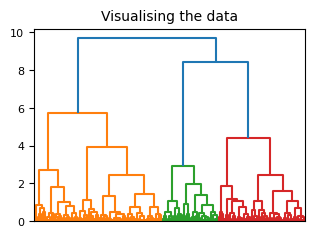

In [19]:
# Step 4: Reducing the dimensionality of the Data 
pca = PCA(n_components = 2) 
X_principal = pca.fit_transform(X_normalized) 
X_principal = pd.DataFrame(X_principal) 
X_principal.columns = ['P1', 'P2'] 
# Step 5: Dendrogram (Very Small Size - No Labels to print quickly)
plt.figure(figsize =(3.5, 2.5)) 
plt.title('Visualising the data', fontsize=10) 
Dendrogram = shc.dendrogram((shc.linkage(X_principal, method ='ward')), no_labels=True) 
plt.tick_params(axis='both', labelsize=8)
plt.show()

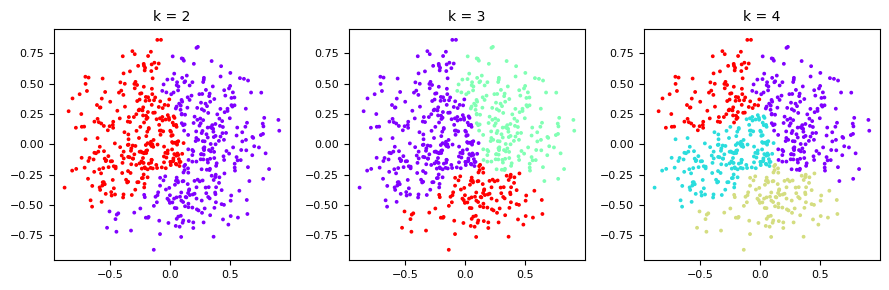

In [20]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(9, 3))
# a) k = 2 
ac2 = AgglomerativeClustering(n_clusters = 2) 
ax1.scatter(X_principal['P1'], X_principal['P2'], c = ac2.fit_predict(X_principal), cmap ='rainbow', s=3) 
ax1.set_title('k = 2', fontsize=10)
ax1.tick_params(labelsize=8)
# b) k = 3
ac3 = AgglomerativeClustering(n_clusters = 3) 
ax2.scatter(X_principal['P1'], X_principal['P2'], c = ac3.fit_predict(X_principal), cmap ='rainbow', s=3) 
ax2.set_title('k = 3', fontsize=10)
ax2.tick_params(labelsize=8)
# c) k = 4
ac4 = AgglomerativeClustering(n_clusters = 4) 
ax3.scatter(X_principal['P1'], X_principal['P2'], c = ac4.fit_predict(X_principal), cmap ='rainbow', s=3) 
ax3.set_title('k = 4', fontsize=10)
ax3.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

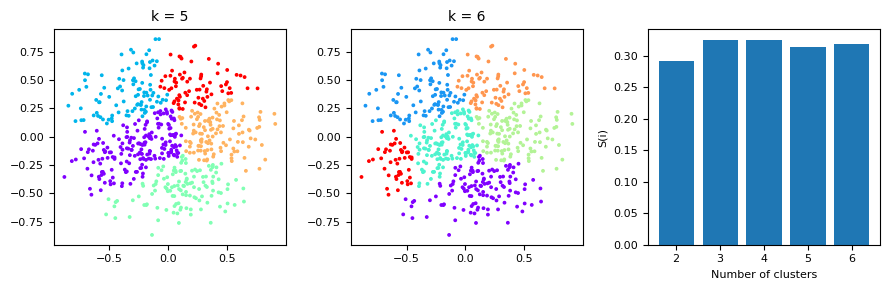

with the help of the silhouette scores, it is concluded that the optimal number of clusters for the given data and clustering technique is 2.


In [21]:
fig, (ax4, ax5, ax6) = plt.subplots(1, 3, figsize=(9, 3))
# d) k = 5
ac5 = AgglomerativeClustering(n_clusters = 5) 
ax4.scatter(X_principal['P1'], X_principal['P2'], c = ac5.fit_predict(X_principal), cmap ='rainbow', s=3) 
ax4.set_title('k = 5', fontsize=10)
ax4.tick_params(labelsize=8)
# e) k = 6
ac6 = AgglomerativeClustering(n_clusters = 6) 
ax5.scatter(X_principal['P1'], X_principal['P2'], c = ac6.fit_predict(X_principal), cmap ='rainbow', s=3) 
ax5.set_title('k = 6', fontsize=10)
ax5.tick_params(labelsize=8)
# Step 7: Silhouette Bar Graph Evaluation
k = [2, 3, 4, 5, 6] 
silhouette_scores = [
    silhouette_score(X_principal, ac2.fit_predict(X_principal)),
    silhouette_score(X_principal, ac3.fit_predict(X_principal)),
    silhouette_score(X_principal, ac4.fit_predict(X_principal)),
    silhouette_score(X_principal, ac5.fit_predict(X_principal)),
    silhouette_score(X_principal, ac6.fit_predict(X_principal))
] 
ax6.bar(k, silhouette_scores) 
ax6.set_xlabel('Number of clusters', fontsize = 8) 
ax6.set_ylabel('S(i)', fontsize = 8)
ax6.tick_params(labelsize=8)
plt.tight_layout()
plt.show()
print("with the help of the silhouette scores, it is concluded that the optimal number of clusters for the given data and clustering technique is 2.")